# 5. 확률/통계: 손실 함수의 수학적 기반

**AI 심화 학습 — `notebooks/probability_loss.ipynb`**

이 노트북은 과제의 다섯 요구사항을 수행한다.

1. 정규분포 $N(0,1)$과 $N(2,0.5)$의 PDF를 한 Figure에 비교
2. 베르누이 분포 $B(0.3)$과 $B(0.7)$의 PMF를 한 Figure에 비교
3. Softmax 직접 구현, 출력의 합과 1의 차이가 $10^{-6}$ 이하인지 검증
4. **정규분포 오차 가정의 MLE $\Leftrightarrow$ MSE 최소화** 유도
5. **베르누이/카테고리 분포 가정의 MLE $\Leftrightarrow$ Cross-Entropy 최소화** 유도

**표기:** 정규분포 $N(\mu,\sigma^2)$의 두 번째 인자는 **분산**이다. 따라서 $N(2,0.5)$의 표준편차는 $\sqrt{0.5}$이다.

**용어:** $\mathcal{L}(\theta)$은 **우도(likelihood)**, $J(\theta)$는 **손실(loss)**로 구별한다. 그래프는 `outputs/`에 PNG로 저장한다.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

np.random.seed(42)

# 주피터 노트북을 프로젝트 루트나 notebooks/에서 열어도 같은 폴더에 저장하도록 처리
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
output_dir = project_root / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

print("결과 저장 폴더:", output_dir.resolve())

결과 저장 폴더: /mnt/data/outputs


## 1. 정규분포 PDF 비교

정규분포의 확률밀도함수(Probability Density Function)는

$$
 f(x\mid\mu,\sigma^2)=\frac{1}{\sqrt{2\pi\sigma^2}}
 \exp\!\left(-\frac{(x-\mu)^2}{2\sigma^2}\right).
$$

- $N(0,1)$: $\mu=0,\;\sigma^2=1$.
- $N(2,0.5)$: $\mu=2,\;\sigma^2=0.5$.

연속확률변수에서 곡선의 **높이**는 확률이 아니라 밀도이며, 구간에 대한 **면적(적분)**이 확률이다.

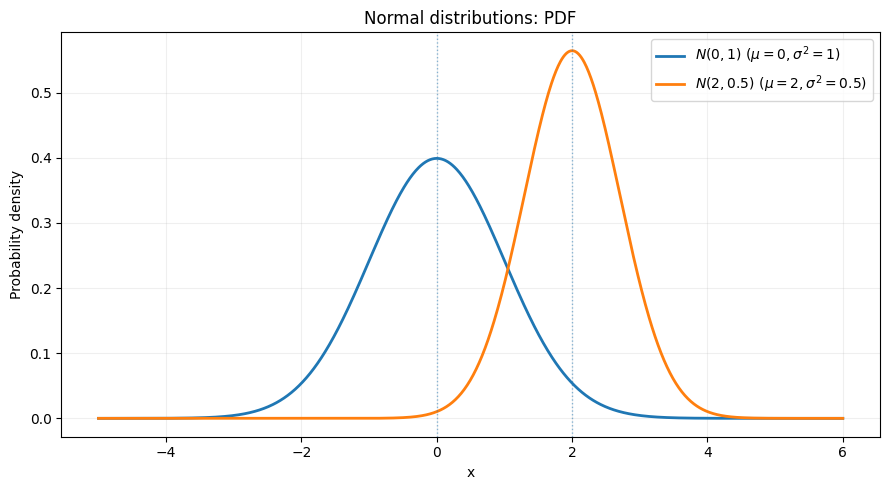

정규분포 PDF 비교 그래프 저장 완료


In [2]:
def normal_pdf(x, mu, variance):
    """평균 mu, 분산 variance인 정규분포의 확률밀도함수(PDF)."""
    if variance <= 0:
        raise ValueError("분산은 양수여야 합니다.")
    return np.exp(-(x - mu)**2 / (2 * variance)) / np.sqrt(2 * np.pi * variance)

x = np.linspace(-5, 6, 1000)
pdf_01 = normal_pdf(x, mu=0, variance=1)
pdf_205 = normal_pdf(x, mu=2, variance=0.5)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x, pdf_01, label=r"$N(0,1)$ ($\mu=0, \sigma^2=1$)", linewidth=2)
ax.plot(x, pdf_205, label=r"$N(2,0.5)$ ($\mu=2, \sigma^2=0.5$)", linewidth=2)
ax.axvline(0, linestyle=":", linewidth=1, alpha=0.5)
ax.axvline(2, linestyle=":", linewidth=1, alpha=0.5)
ax.set(title="Normal distributions: PDF", xlabel="x", ylabel="Probability density")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(output_dir / "normal_pdf_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

assert np.all(pdf_01 >= 0) and np.all(pdf_205 >= 0)
print("정규분포 PDF 비교 그래프 저장 완료")

## 2. 베르누이 PMF 비교

베르누이 확률변수는 $X\in\{0,1\}$이며,

$$P(X=x\mid p)=p^x(1-p)^{1-x},\quad x\in\{0,1\}.$$

따라서 $P(X=0)=1-p$, $P(X=1)=p$. PMF는 **각 값 자체가 나올 확률**을 표현한다.

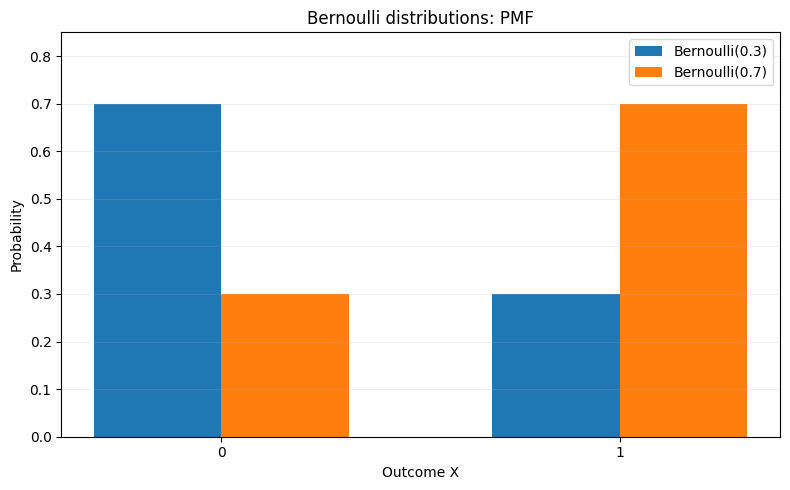

B(0.3): [0.7 0.3] 합계: 1.0
B(0.7): [0.3 0.7] 합계: 1.0


In [3]:
def bernoulli_pmf(x, p):
    """베르누이 분포의 확률질량함수(PMF)."""
    if not 0 <= p <= 1:
        raise ValueError("p는 0과 1 사이여야 합니다.")
    x = np.asarray(x)
    return p**x * (1 - p)**(1 - x)

outcomes = np.array([0, 1])
prob_03 = bernoulli_pmf(outcomes, 0.3)
prob_07 = bernoulli_pmf(outcomes, 0.7)

fig, ax = plt.subplots(figsize=(8, 5))
bar_width = 0.32
ax.bar(outcomes - bar_width/2, prob_03, bar_width, label="Bernoulli(0.3)")
ax.bar(outcomes + bar_width/2, prob_07, bar_width, label="Bernoulli(0.7)")
ax.set(xticks=outcomes, xlabel="Outcome X", ylabel="Probability", title="Bernoulli distributions: PMF", ylim=(0, 0.85))
ax.legend()
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
fig.savefig(output_dir / "bernoulli_pmf_comparison.png", dpi=180, bbox_inches="tight")
plt.show()

assert np.isclose(np.sum(prob_03), 1.0)
assert np.isclose(np.sum(prob_07), 1.0)
print("B(0.3):", prob_03, "합계:", prob_03.sum())
print("B(0.7):", prob_07, "합계:", prob_07.sum())

## 3. Softmax 구현과 합 검증

$K$개 클래스의 점수(logit) $z_k$를 확률로 바꾼다.

$$p_k=\operatorname{softmax}(\mathbf z)_k=\frac{e^{z_k}}{\sum_{j=1}^{K}e^{z_j}}.$$

분모를 공통으로 사용하므로 $\sum_k p_k=1$이다. 계산할 때는 오버플로 방지를 위해 모든 logit에서 최대값 $m=\max_j z_j$를 빼도 된다.

$$\frac{e^{z_k-m}}{\sum_j e^{z_j-m}}=\frac{e^{z_k}}{\sum_j e^{z_j}}.$$

In [4]:
def softmax(logits):
    """1차원 logit 벡터를 안정적으로 확률 벡터로 변환한다."""
    logits = np.asarray(logits, dtype=float)
    if logits.ndim != 1 or logits.size == 0:
        raise ValueError("비어 있지 않은 1차원 벡터가 필요합니다.")
    shifted = logits - np.max(logits)
    exp_values = np.exp(shifted)
    return exp_values / np.sum(exp_values)

for logits in [np.array([2.0, 1.0, 0.0]), np.array([1000.0, 1001.0, 1002.0])]:
    probs = softmax(logits)
    error = abs(np.sum(probs) - 1.0)
    print("logits:", logits)
    print("Softmax:", np.round(probs, 8))
    print("sum:", probs.sum(), "|sum - 1|:", error)
    assert np.all(probs >= 0)
    assert error <= 1e-6, "과제 기준: 오차가 1e-6 이하이어야 합니다."
    print("PASS: 합계 오차 <= 1e-6\n")

logits: [2. 1. 0.]
Softmax: [0.66524096 0.24472847 0.09003057]
sum: 0.9999999999999999 |sum - 1|: 1.1102230246251565e-16
PASS: 합계 오차 <= 1e-6

logits: [1000. 1001. 1002.]
Softmax: [0.09003057 0.24472847 0.66524096]
sum: 0.9999999999999999 |sum - 1|: 1.1102230246251565e-16
PASS: 합계 오차 <= 1e-6



## 4. 수식 유도: **MSE 최소화 = 정규분포 가정하의 MLE**

### 4-1. 모형과 가정

데이터 $D=\{(x_i,y_i)\}_{i=1}^{n}$에서 모델 예측을 $f_\theta(x_i)$라고 하자. 정답은

$$y_i=f_\theta(x_i)+\varepsilon_i,\qquad \varepsilon_i\overset{\mathrm{i.i.d.}}{\sim}N(0,\sigma^2)$$

라고 가정한다. 그러면

$$y_i\mid x_i,\theta\sim N(f_\theta(x_i),\sigma^2),$$

즉, **모델 예측값이 관측값의 정규분포 평균**이다. 여기서는 $\sigma^2>0$이 모든 데이터에 공통이며 **고정된 상수**라고 가정한다.

### 4-2. 우도 함수

한 관측값의 확률밀도는

$$p(y_i\mid x_i,\theta)=\frac{1}{\sqrt{2\pi\sigma^2}}\exp\left[-\frac{(y_i-f_\theta(x_i))^2}{2\sigma^2}\right].$$

오차들이 조건부 독립이므로 전체 **우도**는

$$\mathcal{L}(\theta)=\prod_{i=1}^{n}p(y_i\mid x_i,\theta).$$

### 4-3. 음의 로그우도 전개

로그를 취하면 곱이 합이 된다.

$$
\begin{aligned}
-\log\mathcal{L}(\theta)
&=-\sum_{i=1}^{n}\log p(y_i\mid x_i,\theta)\\
&=\frac{n}{2}\log(2\pi\sigma^2)
+\frac{1}{2\sigma^2}\sum_{i=1}^{n}(y_i-f_\theta(x_i))^2.
\end{aligned}
$$

첫 항은 $\theta$와 무관한 **상수**이고, $1/(2\sigma^2)$는 **양의 상수**이다. 따라서 최대우도추정과 제곱오차 최소화의 해가 동일하다.

$$
\boxed{
\begin{aligned}
\hat\theta_{\mathrm{MLE}}
&=\arg\max_\theta\mathcal{L}(\theta)\\
&=\arg\min_\theta[-\log\mathcal{L}(\theta)]\\
&=\arg\min_\theta\sum_{i=1}^{n}(y_i-f_\theta(x_i))^2\\
&=\arg\min_\theta\underbrace{\frac{1}{n}\sum_{i=1}^{n}(y_i-f_\theta(x_i))^2}_{\mathrm{MSE}}.
\end{aligned}}
$$

**결론:** 관측 오차가 **독립적·동일 분산인 정규분포**라는 가정하에서, 고정 분산을 가진 가우시안 우도를 최대화하는 $\theta$와 MSE를 최소화하는 $\theta$는 같다. NLL과 MSE가 값까지 똑같다는 의미는 아니고 **최적해가 같다는 의미**다.

In [5]:
# 수식 검증: 평균 NLL = 상수 + MSE/(2*variance)
y_true = np.array([1.0, 2.0, 3.0, 4.0])
y_pred = np.array([1.1, 1.8, 3.2, 3.9])
variance = 0.5

mse = np.mean((y_true - y_pred)**2)
mean_nll = -np.mean(np.log(normal_pdf(y_true - y_pred, mu=0, variance=variance)))
expected_nll = 0.5 * np.log(2 * np.pi * variance) + mse / (2 * variance)

print(f"MSE: {mse:.8f}")
print(f"평균 Gaussian NLL: {mean_nll:.8f}")
print(f"상수 + MSE/(2σ²): {expected_nll:.8f}")
assert np.allclose(mean_nll, expected_nll, atol=1e-12)
print("PASS: 가우시안 NLL과 MSE의 관계 확인")

MSE: 0.02500000
평균 Gaussian NLL: 0.59736494
상수 + MSE/(2σ²): 0.59736494
PASS: 가우시안 NLL과 MSE의 관계 확인


## 5. 수식 유도: **Cross-Entropy 최소화 = 베르누이/카테고리 분포 가정하의 MLE**

### 5-1. 이진 분류 — 베르누이 분포와 BCE

각 정답이 $y_i\in\{0,1\}$이고, 신경망의 시그모이드 출력이

$$q_i=P(Y_i=1\mid x_i,\theta)=\sigma(f_\theta(x_i))$$

라고 하자. 실제 관측 정답에 대한 베르누이 PMF는

$$p(y_i\mid x_i,\theta)=q_i^{y_i}(1-q_i)^{1-y_i}.$$

여러 정답이 $\theta$와 입력에 조건부 독립이면

$$\mathcal{L}(\theta)=\prod_{i=1}^{n}q_i^{y_i}(1-q_i)^{1-y_i}.$$

음의 로그를 취해 정리하면

$$
\begin{aligned}
-\log\mathcal{L}(\theta)
&=-\sum_{i=1}^{n}\log\Big[q_i^{y_i}(1-q_i)^{1-y_i}\Big]\\
&=-\sum_{i=1}^{n}\Big[y_i\log q_i+(1-y_i)\log(1-q_i)\Big]\\
&=n\,\mathrm{BCE}(\theta).
\end{aligned}
$$

여기서

$$\mathrm{BCE}(\theta)=-\frac{1}{n}\sum_{i=1}^{n}[y_i\log q_i+(1-y_i)\log(1-q_i)].$$

따라서

$$\boxed{\arg\max_\theta\mathcal{L}(\theta)=\arg\min_\theta\mathrm{BCE}(\theta).}$$

### 5-2. 다중 분류 — 카테고리 분포와 Categorical CE

서로 배타적인 $K$개 클래스 중 하나를 고르는 문제를 생각하자. 출력 logit $\mathbf z_i$에서 **Softmax 확률**을 구한다.

$$q_{ik}=\frac{e^{z_{ik}}}{\sum_{j=1}^K e^{z_{ij}}},\qquad \sum_{k=1}^K q_{ik}=1.$$

정답을 one-hot $y_{ik}\in\{0,1\}$로 나타내면, 한 샘플의 **카테고리 분포 우도**는

$$p(\mathbf y_i\mid x_i,\theta)=\prod_{k=1}^K q_{ik}^{y_{ik}}.$$

$n$개 샘플의 우도에 음의 로그를 취하면

$$
\begin{aligned}
-\log\mathcal{L}(\theta)
&=-\sum_{i=1}^n\sum_{k=1}^{K}y_{ik}\log q_{ik}\\
&=n\,\mathrm{CategoricalCE}(\theta).
\end{aligned}
$$

여기서

$$\mathrm{CategoricalCE}(\theta)=-\frac1n\sum_{i=1}^n\sum_{k=1}^K y_{ik}\log q_{ik}.$$

따라서

$$\boxed{\arg\max_\theta\mathcal{L}(\theta)=\arg\min_\theta\mathrm{CategoricalCE}(\theta).}$$

**정리:** 이진 분류에서는 **베르누이+Sigmoid→BCE**, 단일 클래스 다중 분류에서는 **카테고리+Softmax→Categorical CE**가 음의 로그우도에서 나온다.

In [6]:
# 베르누이 우도와 BCE의 일치 확인
y_binary = np.array([1.0, 0.0, 1.0, 1.0])
q_binary = np.array([0.8, 0.3, 0.9, 0.6])

binary_likelihoods = q_binary**y_binary * (1 - q_binary)**(1 - y_binary)
binary_nll = -np.sum(np.log(binary_likelihoods))
bce = -np.mean(y_binary*np.log(q_binary) + (1 - y_binary)*np.log(1 - q_binary))

print(f"베르누이 총 NLL: {binary_nll:.8f}")
print(f"n × BCE: {len(y_binary)*bce:.8f}")
assert np.allclose(binary_nll, len(y_binary)*bce)

# 카테고리 우도와 Categorical CE의 일치 확인
logits = np.array([2.0, 1.0, 0.0])
q_class = softmax(logits)
y_onehot = np.array([1.0, 0.0, 0.0])

categorical_likelihood = np.prod(q_class**y_onehot)
categorical_nll = -np.log(categorical_likelihood)
categorical_ce = -np.sum(y_onehot*np.log(q_class))

print("클래스별 Softmax 확률:", np.round(q_class, 6))
print(f"카테고리 NLL: {categorical_nll:.8f}")
print(f"Categorical CE: {categorical_ce:.8f}")
assert np.allclose(categorical_nll, categorical_ce)
print("PASS: 베르누이/BCE 및 카테고리/CE 관계 확인")

베르누이 총 NLL: 1.19600463
n × BCE: 1.19600463
클래스별 Softmax 확률: [0.665241 0.244728 0.090031]
카테고리 NLL: 0.40760596
Categorical CE: 0.40760596
PASS: 베르누이/BCE 및 카테고리/CE 관계 확인


## 6. 결과 정리 / 제출 체크리스트

| 요구 사항 | 결과 |
|---|---|
| 정규분포 $N(0,1)$, $N(2,0.5)$ 비교 | `outputs/normal_pdf_comparison.png` |
| 베르누이 $B(0.3)$, $B(0.7)$ 비교 | `outputs/bernoulli_pmf_comparison.png` |
| Softmax와 합계 검증 | 위 출력에서 `PASS`, 오차 $\le10^{-6}$ |
| MSE $\Leftrightarrow$ 정규분포 MLE | **4절** 수식 유도 및 수치 검증 |
| BCE/CE $\Leftrightarrow$ 베르누이/카테고리 MLE | **5절** 수식 유도 및 수치 검증 |

**필수 라이브러리:** NumPy, Matplotlib. 자동미분 라이브러리 사용 없음.